Import bibliotek

In [239]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import sklearn

Weryfikacja pakietów

In [240]:
print(sys.version.split()[0])
print(np.__version__)
print(pd.__version__)
print(mp.__version__)
print(sns.__version__)
print(sklearn.__version__)

2.2.6
2.3.3
3.11.2
0.13.2
1.7.2


Funkcje pomocnicze / wykonawcze

In [241]:
class LRA:
    """
    LRA = Linear Regression Analysis
    """
    def __init__(self, filename: str):
        self.df = pd.read_csv(filename)
        self.a, self.b = self._calculate_parameters()

    def _calculate_parameters(self) -> tuple[float, float]:
        xm: np.float64 = self.df['x'].mean()
        ym: np.float64 = self.df['y'].mean()
        a: np.float64 = ((self.df['x'] - xm) * (self.df['y'] - ym)).sum() / ((self.df['x'] - xm)**2).sum()
        b: np.float64 = ym - a * xm
        return a, b

    @property
    def predicted_y(self) -> pd.Series:
        return self.a * self.df['x'] + self.b

    @property
    def mae(self) -> np.float64:
        '''MAE = Mean Absolute Error'''
        y_pred: pd.Series = self.predicted_y
        return (self.df['y'] - y_pred).abs().mean()

    @property
    def mse(self) -> np.float64:
        '''MSE = Mean Squared Error'''
        y_pred: pd.Series = self.predicted_y
        return ((self.df['y'] - y_pred) ** 2).mean()

    @property
    def rmse(self) -> np.float64:
        '''RMSE = Root Mean Squared Error'''
        return np.sqrt(self.mse)

    def visualize(self) -> None:
        sns.scatterplot(self.df, x='x', y='y')
        x_linia = np.linspace(self.df['x'].min(), self.df['x'].max(), 100)
        plt.plot(x_linia, self.a * x_linia + self.b, color='red')
        plt.show()

# Analiza pliku `reglin_1.csv`

In [242]:
reglin_01 = LRA('reglin_1.csv')

In [243]:
print(f'y = {reglin_01.a}x + {reglin_01.b}')

y = 1.9776566003853109x + -4.903310725531116


In [244]:
print(f'MAE = {reglin_01.mae}')

MAE = 0.7306407201834605


In [245]:
print(f'MSE = {reglin_01.mse}')

MSE = 0.8230711437486876


In [246]:
print(f'RMSE = {reglin_01.rmse}')

RMSE = 0.9072326844579001


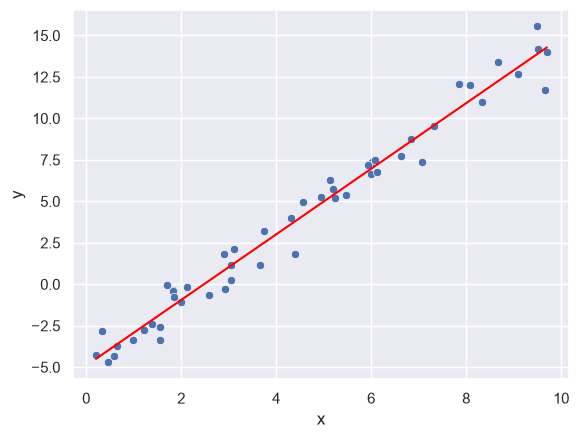

In [247]:
reglin_01.visualize()

### Wnioski / Komentarz:
Wizualizacja pokazuje mniej więcej liniowo ułożone punkty, co znaczy, że regresja liniowa jest wystarczająca. Błędy są dosyć niskie w porównaniu do kolejnych zestawów danych.

# Analiza pliku `reglin_2.csv`

In [248]:
reglin_02 = LRA('reglin_2.csv')

In [249]:
print(f'y = {reglin_02.a}x + {reglin_02.b}')

y = 2.0748983653297883x + -5.440525853813016


In [250]:
print(f'MAE = {reglin_02.mae}')

MAE = 2.563501569050158


In [251]:
print(f'MSE = {reglin_02.mse}')

MSE = 8.344787083468018


In [252]:
print(f'RMSE = {reglin_02.rmse}')

RMSE = 2.8887345124583566


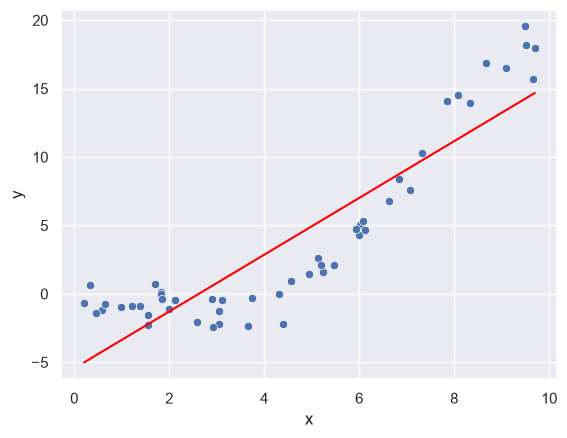

In [253]:
reglin_02.visualize()

### Wnioski / Komentarz:
Wizualizacja nie przedstawia już liniowo ułożonych punktów. Wygląda to na funkcję wykładniczą / części funkcji kwadratowej. Oznacza to, że regresja liniowa nie jest wystarczająca dla tego zestawu danych. Przedstawiają to błędy, które są wyraźnie wyższe niż w modelu `reglin_1.csv`.

# Analiza pliku `reglin_3.csv`

In [254]:
reglin_03 = LRA('reglin_3.csv')

In [255]:
print(f'y = {reglin_03.a}x + {reglin_03.b}')

y = 1.9355461190467909x + -4.79525082790977


In [256]:
print(f'MAE = {reglin_03.mae}')

MAE = 2.6175731982060197


In [257]:
print(f'MSE = {reglin_03.mse}')

MSE = 8.879748816903032


In [258]:
print(f'RMSE = {reglin_03.rmse}')

RMSE = 2.9798907390881015


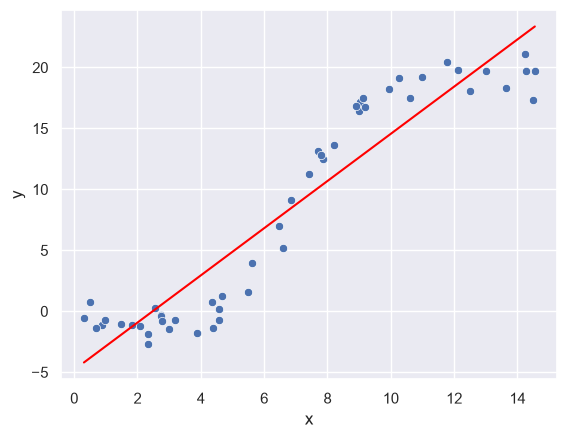

In [259]:
reglin_03.visualize()

### Wnioski / Komentarz:
Wizualizacja nie przedstawia liniowo ułożonych punktów. Wygląda to na funkcję sigmoidalną / część funkcji sinusoidalnej. Regresja liniowa nie jest wystarczająca dla tego zestawu danych. Co ciekawe współczynniki `a` i `b` powstałe dla tego zestawu danych są podobne do tych z zestawu `reglin_1.csv`. Gdyby nie błędy, powstała funkcja byłaby podobna - błędy dają dodatkowy kontekst o jakości współczynników.

Dwie zmienne niezależne `reglin_12.csv`

In [260]:
df12 = pd.read_csv('reglin_12.csv')
df12.info()
df12

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      50 non-null     float64
 1   x2      50 non-null     float64
 2   y       50 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


,x1,x2,y
0,3.745401,6.787092,-7.423853
1,9.507143,5.425930,7.019220
2,7.319939,6.576493,0.159716
3,5.986585,6.263791,-3.636347
4,1.560186,4.185300,-5.005185
5,1.559945,6.453120,-10.651410
6,0.580836,0.619448,5.887931
7,8.661761,1.371880,17.562726
8,6.011150,0.316591,15.103669
9,7.080726,2.277312,11.725687


Import pakietu plotly

In [261]:
import plotly.express as px
import plotly.graph_objects as go

In [262]:
fig = go.Figure()
fig.add_scatter3d(x=df12['x1'], y=df12['x2'], z=df12['y'], mode='markers', marker=dict(color='blue'))
fig.update_layout(title='reglin_12.csv', scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='y'))
fig.show()

Wykorzystanie scikit-learn do regresji

In [263]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [264]:
lr = LinearRegression()
lr.fit(reglin_01.df[['x']], reglin_01.df['y'])
yp = lr.predict(reglin_01.df[['x']])

In [265]:
print('a = ', lr.coef_[0])
print('b = ', lr.intercept_)

a =  1.9776566003853107
b =  -4.903310725531115


Ocena modelu

In [266]:
MAE = mean_absolute_error(reglin_01.df['y'], yp)
MSE = mean_squared_error(reglin_01.df['y'], yp)
RMSE = root_mean_squared_error(reglin_01.df['y'], yp)
R2 = r2_score(reglin_01.df['y'], yp)
print('MAE = ', MAE)
print('MSE = ', MSE)
print('RMSE = ', RMSE)
print('R2 = ', R2)

MAE =  0.7306407201834605
MSE =  0.8230711437486881
RMSE =  0.9072326844579003
R2 =  0.9749140085676858


Ocena modelu `reglin_12.csv`

In [267]:
lr_2 = LinearRegression()
lr_2.fit(df12[['x1', 'x2']], df12['y'])
yp_2 = lr_2.predict(df12[['x1', 'x2']])

In [268]:
print('a1 = ', lr_2.coef_[0])
print('a2 = ', lr_2.coef_[1])
print('b = ', lr_2.intercept_)

a1 =  1.8729619193032725
a2 =  -3.0004508731232846
b =  5.586753915354075


Ocena modelu

In [269]:
MAE_2 = mean_absolute_error(df12['y'], yp_2)
MSE_2 = mean_squared_error(df12['y'], yp_2)
RMSE_2 = root_mean_squared_error(df12['y'], yp_2)
R2_2 = r2_score(df12['y'], yp_2)
print('MAE = ', MAE_2)
print('MSE = ', MSE_2)
print('RMSE = ', RMSE_2)
print('R2 = ', R2_2)

MAE =  0.7070638224462258
MSE =  0.775806368834028
RMSE =  0.8807987107359024
R2 =  0.988230503029934


Wizualizacja modelu

In [270]:
x1_fit = np.linspace(0, 10, 100)
x2_fit = np.linspace(0, 7, 100)
x1_siatka, x2_siatka = np.meshgrid(x1_fit, x2_fit)
y_siatka = lr_2.coef_[0]*x1_siatka + lr_2.coef_[1]*x2_siatka + lr_2.intercept_

In [271]:
fig = go.Figure(data=[go.Surface(x=x1_siatka, y=x2_siatka, z=y_siatka, colorscale=[[0, 'red'], [1, 'red']], showscale=False, opacity=0.6)])
fig.add_scatter3d(x=df12['x1'], y=df12['x2'], z=df12['y'], mode='markers', marker=dict(color='blue'))
fig.update_layout(title='reglin_12.csv', scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='y'))
fig.show()

Regresja wielomianowa

In [272]:
df2 = pd.read_csv('reglin_2.csv')
df2.info()
df2

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


,x,y
0,3.745401,-0.329495
1,9.507143,18.185614
2,7.319939,10.322921
3,5.986585,4.293732
4,1.560186,-2.266792
5,1.559945,-1.508014
6,0.580836,-1.186437
7,8.661761,16.838566
8,6.011150,5.037506
9,7.080726,7.601210


In [273]:
plot = px.scatter(df2, x='x', y='y', trendline='ols')
plot.show()

# Lab 3 - regresja dla x i x^2 (reglin_2.csv)

In [274]:
df2['x2'] = df2['x']**2
df2.info()
df2

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
 2   x2      50 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


,x,y,x2
0,3.745401,-0.329495,14.028030
1,9.507143,18.185614,90.385769
2,7.319939,10.322921,53.581513
3,5.986585,4.293732,35.839198
4,1.560186,-2.266792,2.434182
5,1.559945,-1.508014,2.433429
6,0.580836,-1.186437,0.337371
7,8.661761,16.838566,75.026112
8,6.011150,5.037506,36.133926
9,7.080726,7.601210,50.136678


In [275]:
lr_3 = LinearRegression()
lr_3.fit(df2[['x', 'x2']], df2['y'])
yp_3 = lr_3.predict(df2[['x', 'x2']])

print('a1 = ', lr_3.coef_[0])
print('a2 = ', lr_3.coef_[1])
print('b = ', lr_3.intercept_)

a1 =  -1.3408774147457803
a2 =  0.3502035662278197
b =  -0.03661753964314585


In [276]:
MAE_3 = mean_absolute_error(df2['y'], yp_3)
MSE_3 = mean_squared_error(df2['y'], yp_3)
RMSE_3 = root_mean_squared_error(df2['y'], yp_3)
R2_3 = r2_score(df2['y'], yp_3)
print('MAE = ', MAE_3)
print('MSE = ', MSE_3)
print('RMSE = ', RMSE_3)
print('R2 = ', R2_3)

MAE =  0.9443786339529003
MSE =  1.6257610131060292
RMSE =  1.2750533373573159
R2 =  0.9626730764178592


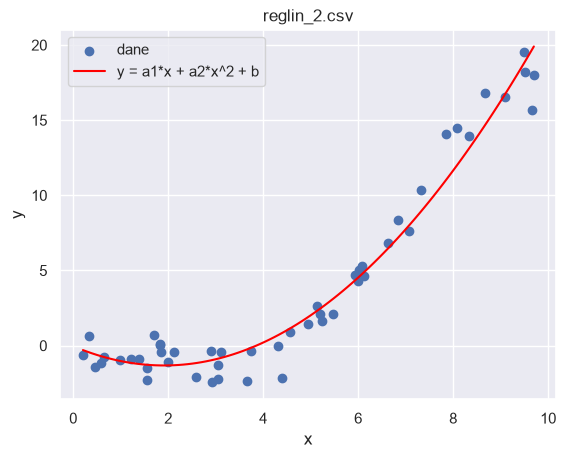

In [277]:
x_fit = np.linspace(df2['x'].min(), df2['x'].max(), 100)
y_fit = lr_3.coef_[0]*x_fit + lr_3.coef_[1]*x_fit**2 + lr_3.intercept_

plt.scatter(df2['x'], df2['y'], label='dane')
plt.plot(x_fit, y_fit, color='red', label='y = a1*x + a2*x^2 + b')
plt.title('reglin_2.csv')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# Regresja dla x, x^2 i x^3 (reglin_3.csv)

In [278]:
df3 = pd.read_csv('reglin_3.csv')
df3['x2'] = df3['x']**2
df3['x3'] = df3['x']**3
df3.info()
df3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
 2   x2      50 non-null     float64
 3   x3      50 non-null     float64
dtypes: float64(4)
memory usage: 1.7 KB


,x,y,x2,x3
0,5.618102,3.921815,31.563068,177.324527
1,14.260715,19.737921,203.367981,2900.172732
2,10.979909,19.235973,120.558404,1323.720325
3,8.979877,16.446945,80.638196,724.121100
4,2.340280,-2.646678,5.476909,12.817498
5,2.339918,-1.887835,5.475215,12.811554
6,0.871254,-1.113187,0.759084,0.661355
7,12.992642,19.706251,168.808751,2193.271700
8,9.016725,17.194074,81.301333,733.071775
9,10.621089,17.527136,112.807524,1198.138720


In [279]:
lr_4 = LinearRegression()
lr_4.fit(df3[['x', 'x2', 'x3']], df3['y'])
yp_4 = lr_4.predict(df3[['x', 'x2', 'x3']])

print('a1 = ', lr_4.coef_[0])
print('a2 = ', lr_4.coef_[1])
print('a3 = ', lr_4.coef_[2])
print('b = ', lr_4.intercept_)

a1 =  -3.3336933473043
a2 =  0.9262384480317617
a3 =  -0.04260231358356603
b =  1.4277378916752088


In [280]:
MAE_4 = mean_absolute_error(df3['y'], yp_4)
MSE_4 = mean_squared_error(df3['y'], yp_4)
RMSE_4 = root_mean_squared_error(df3['y'], yp_4)
R2_4 = r2_score(df3['y'], yp_4)
print('MAE = ', MAE_4)
print('MSE = ', MSE_4)
print('RMSE = ', RMSE_4)
print('R2 = ', R2_4)

MAE =  1.138354713702911
MSE =  1.8311230521237365
RMSE =  1.3531899541911092
R2 =  0.976469155967986


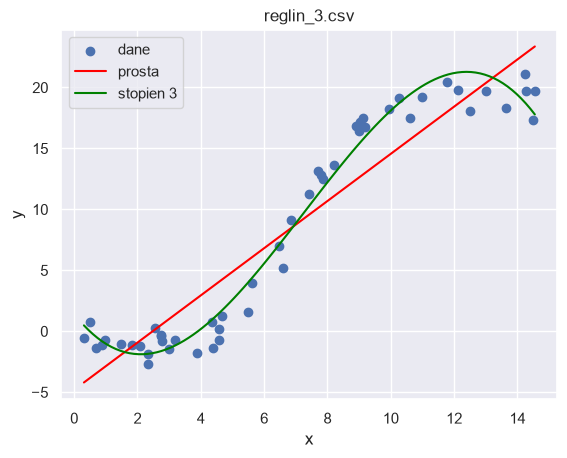

In [281]:
x_fit_3 = np.linspace(df3['x'].min(), df3['x'].max(), 100)
y_fit_3 = lr_4.coef_[0]*x_fit_3 + lr_4.coef_[1]*x_fit_3**2 + lr_4.coef_[2]*x_fit_3**3 + lr_4.intercept_

plt.scatter(df3['x'], df3['y'], label='dane')
plt.plot(x_fit_3, reglin_03.a*x_fit_3 + reglin_03.b, color='red', label='prosta')
plt.plot(x_fit_3, y_fit_3, color='green', label='stopien 3')
plt.title('reglin_3.csv')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# Generowanie cech wielomianowych (PolynomialFeatures)

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
sklearn.set_config(transform_output='pandas')
pf2 = PolynomialFeatures(2, include_bias=False)
pf2.fit_transform(df3[['x']])

In [ ]:
cechy2 = pd.DataFrame(pf2.fit_transform(df3[['x']]), columns=pf2.get_feature_names_out())
cechy2

In [ ]:
pf3 = PolynomialFeatures(3, include_bias=False)
cechy3 = pd.DataFrame(pf3.fit_transform(df3[['x']]), columns=pf3.get_feature_names_out())

lr_5 = LinearRegression()
lr_5.fit(cechy3, df3['y'])
yp_5 = lr_5.predict(cechy3)

print('a1 = ', lr_5.coef_[0])
print('a2 = ', lr_5.coef_[1])
print('a3 = ', lr_5.coef_[2])
print('b = ', lr_5.intercept_)

In [ ]:
MAE_5 = mean_absolute_error(df3['y'], yp_5)
MSE_5 = mean_squared_error(df3['y'], yp_5)
RMSE_5 = root_mean_squared_error(df3['y'], yp_5)
R2_5 = r2_score(df3['y'], yp_5)
print('MAE = ', MAE_5)
print('MSE = ', MSE_5)
print('RMSE = ', RMSE_5)
print('R2 = ', R2_5)

# Zadanie - cechy wielomianowe z PolynomialFeatures

reglin_2.csv - stopien 2

In [ ]:
dane2 = pd.read_csv('reglin_2.csv')

pf_r2 = PolynomialFeatures(2, include_bias=False)
cechy_r2 = pd.DataFrame(pf_r2.fit_transform(dane2[['x']]), columns=pf_r2.get_feature_names_out())
cechy_r2

In [ ]:
lr_r2 = LinearRegression()
lr_r2.fit(cechy_r2, dane2['y'])
yp_r2 = lr_r2.predict(cechy_r2)

print('wspolczynniki = ', lr_r2.coef_)
print('b = ', lr_r2.intercept_)
print('MAE = ', mean_absolute_error(dane2['y'], yp_r2))
print('MSE = ', mean_squared_error(dane2['y'], yp_r2))
print('RMSE = ', root_mean_squared_error(dane2['y'], yp_r2))
print('R2 = ', r2_score(dane2['y'], yp_r2))

In [ ]:
x_wykres = pd.DataFrame({'x': np.linspace(dane2['x'].min(), dane2['x'].max(), 100)})
cechy_wykres = pd.DataFrame(pf_r2.transform(x_wykres), columns=pf_r2.get_feature_names_out())
y_wykres = lr_r2.predict(cechy_wykres)

plt.scatter(dane2['x'], dane2['y'], label='dane')
plt.plot(x_wykres['x'], y_wykres, color='red', label='stopien 2')
plt.title('reglin_2.csv')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

reglin_3.csv - stopien 3

In [ ]:
dane3 = pd.read_csv('reglin_3.csv')

pf_r3 = PolynomialFeatures(3, include_bias=False)
cechy_r3 = pd.DataFrame(pf_r3.fit_transform(dane3[['x']]), columns=pf_r3.get_feature_names_out())
cechy_r3

In [ ]:
lr_r3 = LinearRegression()
lr_r3.fit(cechy_r3, dane3['y'])
yp_r3 = lr_r3.predict(cechy_r3)

print('wspolczynniki = ', lr_r3.coef_)
print('b = ', lr_r3.intercept_)
print('MAE = ', mean_absolute_error(dane3['y'], yp_r3))
print('MSE = ', mean_squared_error(dane3['y'], yp_r3))
print('RMSE = ', root_mean_squared_error(dane3['y'], yp_r3))
print('R2 = ', r2_score(dane3['y'], yp_r3))

In [ ]:
x_wykres = pd.DataFrame({'x': np.linspace(dane3['x'].min(), dane3['x'].max(), 100)})
cechy_wykres = pd.DataFrame(pf_r3.transform(x_wykres), columns=pf_r3.get_feature_names_out())
y_wykres = lr_r3.predict(cechy_wykres)

plt.scatter(dane3['x'], dane3['y'], label='dane')
plt.plot(x_wykres['x'], y_wykres, color='red', label='stopien 3')
plt.title('reglin_3.csv')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

reglin_12a.csv - dwie zmienne, stopien 2

In [ ]:
dane12a = pd.read_csv('reglin_12a.csv')

pf_r12a = PolynomialFeatures(2, include_bias=False)
cechy_r12a = pd.DataFrame(pf_r12a.fit_transform(dane12a[['x1', 'x2']]), columns=pf_r12a.get_feature_names_out())
cechy_r12a

In [ ]:
lr_r12a = LinearRegression()
lr_r12a.fit(cechy_r12a, dane12a['y'])
yp_r12a = lr_r12a.predict(cechy_r12a)

for nazwa, a in zip(pf_r12a.get_feature_names_out(), lr_r12a.coef_):
    print(nazwa, '=', a)
print('b = ', lr_r12a.intercept_)
print('MAE = ', mean_absolute_error(dane12a['y'], yp_r12a))
print('MSE = ', mean_squared_error(dane12a['y'], yp_r12a))
print('RMSE = ', root_mean_squared_error(dane12a['y'], yp_r12a))
print('R2 = ', r2_score(dane12a['y'], yp_r12a))

In [ ]:
x1_s, x2_s = np.meshgrid(np.linspace(0, 10, 50), np.linspace(0, 7, 50))
siatka = pd.DataFrame({'x1': x1_s.ravel(), 'x2': x2_s.ravel()})
cechy_siatka = pd.DataFrame(pf_r12a.transform(siatka), columns=pf_r12a.get_feature_names_out())
y_s = lr_r12a.predict(cechy_siatka).reshape(x1_s.shape)

fig = go.Figure(data=[go.Surface(x=x1_s, y=x2_s, z=y_s, colorscale=[[0, 'red'], [1, 'red']], showscale=False, opacity=0.6)])
fig.add_scatter3d(x=dane12a['x1'], y=dane12a['x2'], z=dane12a['y'], mode='markers', marker=dict(color='blue'))
fig.update_layout(title='reglin_12a.csv - stopien 2', scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='y'))
fig.show()

In [ ]:
for stopien in [1, 2, 3]:
    pf = PolynomialFeatures(stopien, include_bias=False)
    cechy = pf.fit_transform(dane12a[['x1', 'x2']])
    model = LinearRegression().fit(cechy, dane12a['y'])
    rmse = root_mean_squared_error(dane12a['y'], model.predict(cechy))
    print('stopien', stopien, '- liczba cech:', cechy.shape[1], '- RMSE =', rmse)